# From Tensors to Neural Networks in PyTorch

---

Prof. Dr.-Ing. Antje Muntzinger, Hochschule für Technik Stuttgart

antje.muntzinger@hft-stuttgart.de

---

This notebook is loosely based on Udacity's *Deep Learning Nanodegree*.

In this notebook, you'll get introduced to [PyTorch](http://pytorch.org/), a framework for building and training neural networks. PyTorch in a lot of ways behaves like the arrays you know from Numpy. These Numpy arrays, after all, are just tensors. PyTorch takes these tensors and makes it simple to move them to GPUs for the faster processing needed when training neural networks. It also provides a module that automatically calculates gradients (for backpropagation!) and another module specifically for building neural networks. All together, PyTorch ends up being more coherent with Python and the Numpy/Scipy stack compared to TensorFlow and other frameworks.

In [26]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(11) # set random seed for reproducibility


## 1. Tensors and shapes


Deep Learning is based on artificial neural networks which have been around in some form since the late 1950s. The networks are built from individual parts approximating neurons, typically called units or simply "neurons." Each unit has some number of weighted inputs. These weighted inputs are summed together (a linear combination) then passed through an activation function to get the unit's output.

<img src="images/simple_neuron.png" width=400px>

Mathematically this looks like: 

\begin{align*}
y &= f(w_1 x_1 + w_2 x_2 + b) \\
y &= f\left(\sum_i w_i x_i +b \right)
\end{align*}

With vectors this is the dot/inner product of two vectors:

$$
h = \begin{bmatrix}
x_1 \, x_2 \cdots  x_n
\end{bmatrix}
\cdot 
\begin{bmatrix}
           w_1 \\
           w_2 \\
           \vdots \\
           w_n
\end{bmatrix}
$$

## Tensors

It turns out neural network computations are just a bunch of linear algebra operations on *tensors*, a generalization of matrices. A vector is a 1-dimensional tensor, a matrix is a 2-dimensional tensor, an array with three indices is a 3-dimensional tensor (RGB color images for example). The fundamental data structure for neural networks are tensors and PyTorch (as well as pretty much every other deep learning framework) is built around tensors.

<img src="images/tensor_examples.svg" width=600px>

In [27]:
# some practical examples of using PyTorch tensors
x = torch.tensor([[0.2, 0.7], [-0.4, 0.1]], dtype=torch.float32)
w = torch.tensor([[1.0], [-2.0]])
b = torch.tensor([0.5])
print('Input shape:', x.shape)
print('Layer output:', x @ w + b) # matrix multiplication with @ operator


Input shape: torch.Size([2, 2])
Layer output: tensor([[-0.7000],
        [-0.1000]])


**TODO:** Why does the summation above work? This should astonish you!

**HINT:** Look up what broadcasting means in PyTorch.

**ANSWER:** The summation works because of broadcasting. In PyTorch, when performing operations on tensors of different shapes, the smaller tensor is "broadcast" across the larger tensor so that they have compatible shapes. In this case, the bias tensor `b` has shape `(1,)`, which is broadcasted to match the shape of the result of `x @ w`, allowing for element-wise addition.

## 2. Autograd: let PyTorch apply the chain rule

Torch provides a module, `autograd`, for automatically calculating the gradients of tensors. We can use it to calculate the gradient of the loss with respect to all our parameters. Autograd works by keeping track of operations performed on tensors, then going backwards through those operations, calculating gradients along the way. To make sure PyTorch keeps track of operations on a tensor and calculates the gradients, you need to set `requires_grad = True` on a tensor. You can do this at creation with the `requires_grad` keyword, or at any time with `x.requires_grad_(True)`.

You can turn off gradients for a block of code with the `torch.no_grad()` content:


In [28]:
x = torch.zeros(1, requires_grad=True)

with torch.no_grad():
    y = x * 2

print(x.requires_grad)
print(y.requires_grad)

True
False


The gradients are computed with respect to some variable `z` with `z.backward()`. This does a backward pass through the operations that created `z`. For example, we can define `z` as the mean of the squared input data. We can calculate the gradient for `z` with respect to each `w_j`, with `n=4`:

$$
\frac{\partial z}{\partial w_j} = \frac{\partial}{\partial w_j}\left[\frac{1}{n}\sum_i^n w_i^2\right] = \frac{\partial}{\partial w_j}\left[\frac{1}{4}(w_1^2+w_2^2+w_3^2+w_4^2)\right] = \frac{1}{4}\cdot 2w_j = \frac{w_j}{2}
$$

In [29]:
# Autograd example: compute the gradient of a simple loss function
w = torch.tensor([1.0, -2.0, 3.0], requires_grad=True)
loss = (w ** 2).mean()
print('Before backward pass - Autograd:', w.grad)
loss.backward()
print('After backward pass - Autograd:', w.grad)

# A NEW forward pass builds a new graph; backward adds to the existing gradient.
(w ** 2).mean().backward()
print('After a second backward pass:', w.grad)
w.grad = None


Before backward pass - Autograd: None
After backward pass - Autograd: tensor([ 0.6667, -1.3333,  2.0000])
After a second backward pass: tensor([ 1.3333, -2.6667,  4.0000])


**TODO:** Make sure that the analytical derivative gives the same result as the autograd computed gradient. 

**HINT:** As derived above, the analytical derivative of the mean squared loss function is given by 2 * w / n, where n is the number of elements in w. You can compute this using `w.detach()` to get the tensor without gradient tracking, and `w.numel()` to get the number of elements in w. Alternatively, you can calculate the derivatives with pen and paper.

In [30]:
# YOUR CODE HERE
print('Analytical derivative:', 2 * w.detach() / w.numel()) # analytical derivative of the mean squared loss function, using w.detach() to get the tensor without gradient tracking, and w.numel() to get the number of elements in w


Analytical derivative: tensor([ 0.6667, -1.3333,  2.0000])


## 3. Data: two noisy rings

Next, we generate our data. The inputs are two coordinates; the target is 0 for the inner ring and 1 for the outer ring. We generate independent **training** and **validation** samples; this teaching demo has no separate final test.

Inputs: torch.Size([600, 2]) Targets: torch.Size([600, 1])


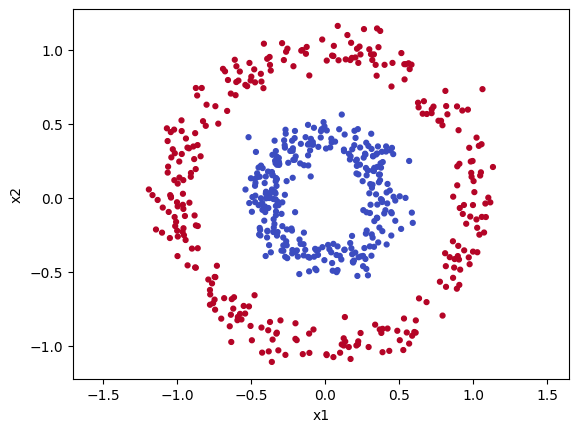

In [31]:
def make_rings(n, generator):
    labels = torch.arange(n) % 2
    angle = 2 * torch.pi * torch.rand(n, generator=generator)
    radius = torch.where(labels == 0, 0.4, 1.0)
    points = radius[:, None] * torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)
    points += 0.08 * torch.randn(n, 2, generator=generator)
    return points, labels.float().reshape(-1, 1)

x_train, y_train = make_rings(600, torch.Generator().manual_seed(11))
x_val, y_val = make_rings(300, torch.Generator().manual_seed(12))

# TensorDataset pairs each input with its target; DataLoader forms mini-batches.
trainloader = DataLoader(TensorDataset(x_train, y_train), batch_size=64, shuffle=True,
                         generator=torch.Generator().manual_seed(11), num_workers=0)
print('Inputs:', x_train.shape, 'Targets:', y_train.shape)
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train[:, 0], cmap='coolwarm', s=12)
plt.xlabel('x1'); plt.ylabel('x2'); plt.axis('equal'); plt.show()


**TODO:** Can we solve this classification problem with a simple neuron? 

**ANSWER:** No, a simple neuron (linear model) cannot solve this problem because the data is not linearly separable, no straight line can separate the two classes in the input space. A more complex model, such as a neural network with non-linear activation functions, is required.

## 4. Define the network

Now we use the basic PyTorch components to define our network: `nn.Module` collects the trainable parameters; `__init__` defines the layers; `forward` describes how the input passes through them. `nn.Linear(2,16)` learns a weight and bias for each of 16 hidden units. ReLU applies $\max(0,z)$ and makes the network non-linear.

The final layer returns one **logit** per sample: a real-valued score, not yet a probability. `BCEWithLogitsLoss` combines sigmoid and binary cross entropy in a numerically stable way. We apply sigmoid only when displaying probabilities.


In [32]:
class RingNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 16)
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        return self.fc2(x)  # raw logits; no sigmoid here

model = RingNet()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))


RingNet(
  (fc1): Linear(in_features=2, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 65


**TODO:** Do some research on why we output the raw logits from the model and use `BCEWithLogitsLoss` instead of applying a sigmoid activation in the model's forward pass. 

**ANSWER:** This is done for numerical stability. The `BCEWithLogitsLoss` combines the sigmoid activation and the binary cross-entropy loss in a single function, which helps to avoid issues with very small or very large values that can occur when applying the sigmoid function separately. In theory, both approaches should yield the same result, but in practice, using `BCEWithLogitsLoss` is more stable.

**TODO**: Define a second neural network with two hidden layers. Start by copying the `RingNet` class in the previous cell. Make sure to use ReLU activation functions after each hidden layer. Instanciate the model, define the loss function and optimizer, and print the model summary and number of trainable parameters. Which dimensions in the layers can you choose freely, and which are determined by the input and output dimensions?

In [33]:
# YOUR CODE HERE
class TwoHiddenNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 32)  # First hidden layer with 32 neurons
        self.fc2 = nn.Linear(32, 16)  # Second hidden layer with 16 neurons
        self.fc3 = nn.Linear(16, 1)   # Output layer

    def forward(self, x):
        x = torch.relu(self.fc1(x))   # ReLU activation after first hidden layer
        x = torch.relu(self.fc2(x))   # ReLU activation after second hidden layer
        return self.fc3(x)             # Raw logits; no sigmoid here

model2 = TwoHiddenNet()
criterion2 = nn.BCEWithLogitsLoss()
optimizer2 = torch.optim.Adam(model2.parameters(), lr=0.02)
print(model2)
print('Trainable parameters:', sum(p.numel() for p in model2.parameters()))

TwoHiddenNet(
  (fc1): Linear(in_features=2, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 641


**ANSWER**: The input dimension is determined by the shape of the input data (2 in this case), and the output dimension is determined by the shape of the target data (1 in this case). The number of neurons in the hidden layers can be chosen freely, but we should avoid making them too small or too large, as this can lead to underfitting or overfitting, respectively. A good starting point is to use a number of neurons that is between the input and output dimensions, and then experiment with different sizes to see what works best for the specific problem.

## 5. One training step

Let's take a look at a single training step - you will see these steps over and over again in different applications!


In [34]:
inputs, targets = next(iter(trainloader)) # get a single batch of data
model.train() # set the model to training mode (best practice, not strictly necessary here)
optimizer.zero_grad() # clear the gradients of all optimized tensors
logits = model(inputs) # compute the model output (logits) for the batch = forward pass
loss = criterion(logits, targets) # compute the loss for the batch
loss.backward() # compute the gradients of the loss w.r.t. model parameters = backward pass
print('Batch loss:', loss.item()) 
print('First-layer gradient norm:', model.fc1.weight.grad.norm().item())
optimizer.step() # update the model parameters based on the computed gradients


Batch loss: 0.6960656046867371
First-layer gradient norm: 0.028767937794327736


## 6. Train for several epochs
Let's train the model for several epochs and visualize the training and validation loss.

An **epoch** is one pass through all training samples. A **mini-batch** provides one parameter update by processing a small subset of the training data of a fixed size (the batch size). We start with a fresh model and optimizer so rerunning this cell starts a new experiment.

During validation, `model.eval()` sets layers to evaluation mode. `torch.no_grad()` separately disables gradient tracking. Neither performs a parameter update. Using `model.eval()` will become more important later, so it is best practice to always use it during validation.


In [35]:
torch.manual_seed(11)
model = RingNet()
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
train_losses, val_losses = [], []

for epoch in range(60):
    model.train()
    loss_sum = 0.0
    for inputs, targets in trainloader:

        # The following lines are the core of the training loop, implementing the forward and backward passes:
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        # Weight each batch by its size, including the smaller last batch.
        loss_sum += loss.item() * len(inputs)
    train_losses.append(loss_sum / len(x_train))

    # Evaluate the model on the validation set without computing gradients.
    model.eval()
    with torch.no_grad():
        val_logits = model(x_val)
        val_loss = criterion(val_logits, y_val).item()
        val_accuracy = ((val_logits >= 0) == y_val.bool()).float().mean().item()
    val_losses.append(val_loss)
    if (epoch + 1) % 15 == 0:
        print(f'Epoch {epoch+1:2d}: train loss {train_losses[-1]:.4f}, '
              f'val loss {val_loss:.4f}, val accuracy {val_accuracy:.1%}')


Epoch 15: train loss 0.0271, val loss 0.0242, val accuracy 100.0%
Epoch 30: train loss 0.0077, val loss 0.0067, val accuracy 100.0%
Epoch 45: train loss 0.0039, val loss 0.0033, val accuracy 100.0%
Epoch 60: train loss 0.0024, val loss 0.0020, val accuracy 100.0%


## 7. Inspect the result

Finally, let's take a look at the results! 


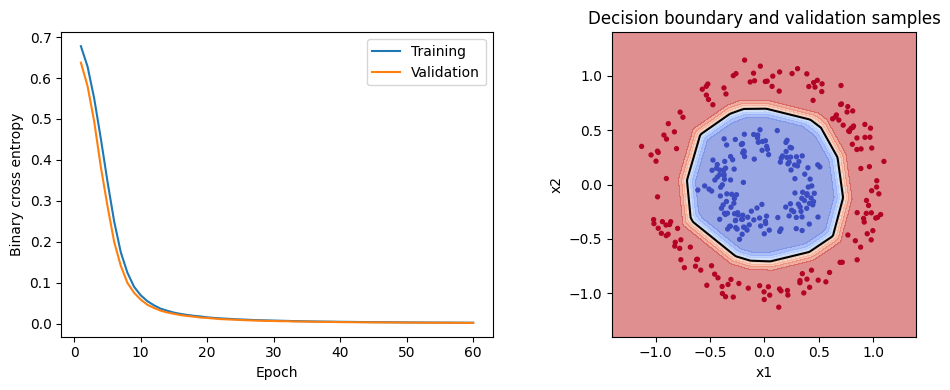

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(range(1, 61), train_losses, label='Training')
axes[0].plot(range(1, 61), val_losses, label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Binary cross entropy')
axes[0].legend()

axis = torch.linspace(-1.4, 1.4, 160)
g1, g2 = torch.meshgrid(axis, axis, indexing='ij')
grid = torch.stack([g1.flatten(), g2.flatten()], dim=1)
model.eval()
with torch.no_grad():
    p = torch.sigmoid(model(grid)).reshape(g1.shape).numpy() # apply sigmoid to the logits to get probabilities
axes[1].contourf(g1.numpy(), g2.numpy(), p, levels=np.linspace(0, 1, 11),
                 cmap='coolwarm', alpha=0.55)
axes[1].contour(g1.numpy(), g2.numpy(), p, levels=[0.5], colors='black')
axes[1].scatter(x_val[:, 0], x_val[:, 1], c=y_val[:, 0], cmap='coolwarm', s=8)
axes[1].set(xlabel='x1', ylabel='x2', title='Decision boundary and validation samples')
axes[1].set_aspect('equal')
plt.tight_layout(); plt.show()


**TODO:** Answer the following questions:

- How do you interpret the loss curves above?
- What happens if we remove ReLU? 
- Why do we need `zero_grad()`? 
- Which quantities are learned, and which ones do we choose ourselves?


 
**ANSWER:** 

- The decreasing training and validation loss curves indicate that the model is learning to fit the training data and generalize to unseen validation data. If the validation loss starts to increase while the training loss continues to decrease, it may indicate overfitting, but this is not the case here.
- Removing ReLU would make the model linear, which would not be able to capture the non-linear decision boundary of the rings dataset. The model would likely perform poorly on this task.
- We need `zero_grad()` to clear the gradients of all optimized tensors before the next backward pass. If we don't do this, the gradients would accumulate from previous backward passes, leading to incorrect updates.
- The model learns the model parameters (weights and biases) that minimize the loss function on the training data. We as developers get to choose the hyperparameters (like learning rate, number of layers, number of neurons per layer, etc.)